# Introduction: The Anatomy of Anime Popularity

Welcome to the core of the anime industry's success metrics. While our previous analysis explored the historical evolution of the medium, this notebook shifts the focus to the mechanics of modern popularity. What exactly makes a series a cultural phenomenon? Is it the safety of a popular manga adaptation, or the creative risk of an original story? Do blockbuster voice actors guarantee a hit, and which animation studios have cracked the code to consistent success? By analyzing millions of user interactions, ratings, and favorites, we aim to uncover the hidden patterns driving the community's preferences. Whether you are a fan looking for your next binge-watch or a journalist investigating the "Star System" of the animation industry, this interactive analysis will map out the landscape of what we watch, why we love it, and who is pulling the strings behind the scenes.

In [1]:
# Library imports

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys, os
sys.path.insert(0, os.path.abspath('../src'))
from utils import *

In [2]:
# Load data

data = load_data(['details', 'characters', 'character_anime_works', 'ratings', 'profiles', 'stats', 'person_voice_works', 'person_details'], data_path='../data/')
details = data["details"]
characters = data["characters"]
character_anime_works = data["character_anime_works"]
ratings = data["ratings"]
profiles = data["profiles"]
stats = data["stats"]
person_voice_works = data["person_voice_works"]
person_details = data["person_details"]
data = None

details: 28,888 righe
characters: 209,506 righe
character_anime_works: 236,816 righe
ratings: 93,091,180 righe
profiles: 337,155 righe
stats: 28,955 righe
person_voice_works: 488,565 righe
person_details: 76,594 righe


## What we are actually watching?

Before diving into the complex mechanics of the industry, we need to establish the baseline of community behavior. By comparing the top 15 most-viewed anime against the top 15 highest-rated, a clear discrepancy emerges.

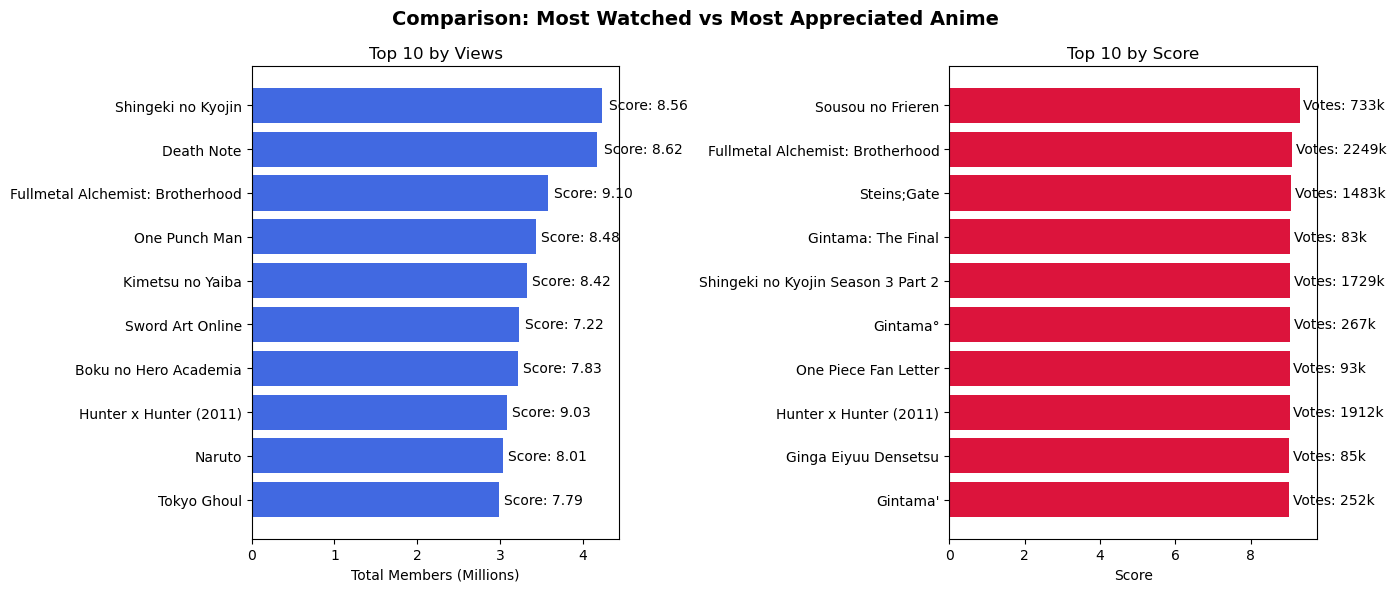

In [3]:
stats_detail = stats.merge(details, on='mal_id')
top_viewed_10 = stats_detail.nlargest(10, 'total')[['title', 'total', 'score']]
top_rated_10 = details[details['scored_by'] >= 1000].nlargest(10, 'score')[['title', 'score', 'scored_by']]

plot_comparison_side_by_side(top_viewed_10, top_rated_10)


### Popularity vs. Prestige

Take a close look at those two lists. Aside from a couple of rare, universally acclaimed exceptions like _Fullmetal Alchemist: Brotherhood_ and _Hunter x Hunter_, it becomes immediately clear that popularity and prestige rarely overlap.

The most-watched shows—titans like _Death Note_, _Attack on Titan_, and _Naruto_ pull in massive, general audiences. Because they reach such a wide demographic with varying tastes, their overall scores tend to average out. On the flip side, the highest-rated shows tell a completely different story. Critical darlings like _Sousou no Frieren_ or the _Gintama_ franchise often sit at a fraction of the viewership. The data reveals a harsh truth of the industry: mainstream popularity guarantees millions of eyes through accessibility and hype, but the highest ratings are usually awarded by smaller, highly dedicated fanbases rewarding niche masterpieces. **Popularity gets you an audience; quality gets you a legacy**.

---

## Does Category Dictate Success?

If quality and popularity don't perfectly align, does the genre of a show give it an inherent advantage? Let's look at how the sheer volume of shows produced in specific genres compares to how the community actually rates them.

Unique genres: 21


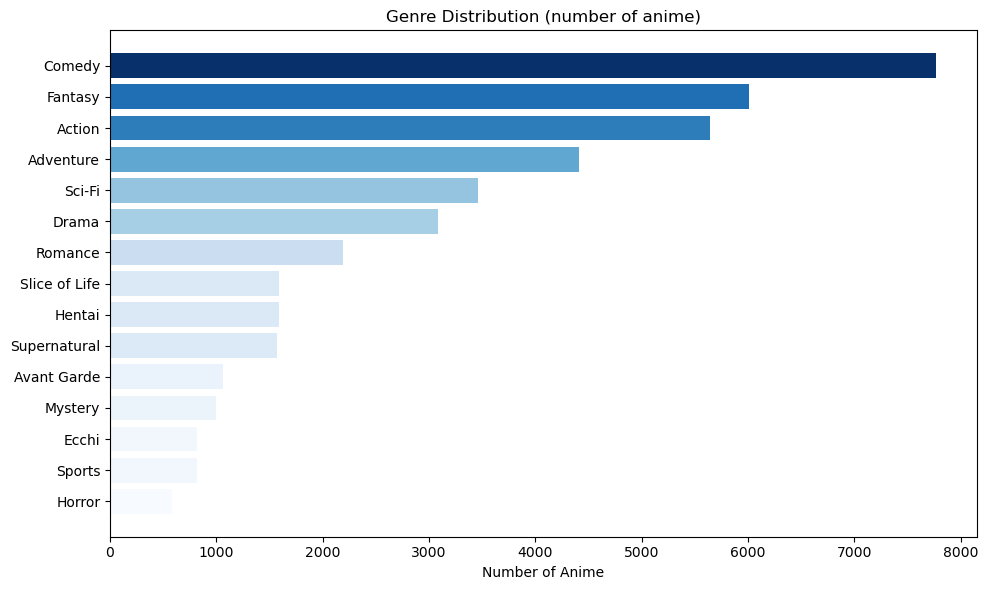

In [4]:
details_genres = details.explode("genres")
print(f"Unique genres: {details_genres["genres"].dropna().nunique()}")
genre_counts = details_genres["genres"].value_counts().head(15).reset_index()
genre_counts.columns = ["genre", "count"]
plot_hbar(genre_counts, label_col="genre", val_col="count", color_col="count",
          cmap="Blues", annot_fmt="{:,.0f}",
          title="Genre Distribution (number of anime)", xlabel="Number of Anime")

### The Pillars of Anime Production

Looking at the sheer volume of titles produced, a clear "holy trinity" emerges: **Comedy, Fantasy, and Action**. These three genres overwhelmingly dominate the historical landscape of anime. This distribution highlights an industry historically driven by escapism and high-energy entertainment. Conversely, genres like Sports and Horror make up a significantly smaller fraction of the medium, suggesting they are either viewed as higher-risk investments by production committees or serve a highly specialized, dedicated niche. 

### What Dominates Each Category?

We have established that some genres are produced in massive volumes while others are critical darlings. But when we look at the absolute peak of each category, who are the reigning champions? 

To understand the specific tastes of the community, **we isolated the top 10 most popular anime across various genres**. Instead of overwhelming you with a massive static chart, we have built an interactive explorer. This allows you to dissect the "Hall of Fame" for any genre you are interested in.


In [5]:
show_genre_explorer(details_genres)

interactive(children=(Dropdown(description='Genre:', layout=Layout(width='300px'), options=('Action', 'Adventu…

#### Franchise Monopolies

Certain genres are completely cannibalized by single, highly successful franchises. 
**Comedy** is practically a tribute to *Gintama*, occupying almost the entire Top 10 with scores consistently above 8.90. * **Suspense** is heavily dominated by the various final seasons of *Shingeki no Kyojin* (Attack on Titan) and *Steins;Gate*. 
**Slice of Life** is a two-horse race between the critically acclaimed *Mushishi* and *Natsume Yuujinchou* series. This indicates that sequels of beloved series benefit immensely from "survivorship bias"—only dedicated fans watch the later seasons, practically guaranteeing inflated, sky-high scores.

#### The "Genre Ceiling" Effect:

There is a severe discrepancy in what scores are achievable depending on the genre. Mainstream categories like *Drama*, *Sci-Fi*, and *Action/Adventure* easily breach the **9.0** threshold. Conversely, niche genres face a harsh "score ceiling." 
The **Avant Garde** genre peaks at **8.56** (*Evangelion*), **Horror** peaks at **8.60** (*Berserk*), and **Erotica** struggles to pass **7.44** (*Fuyu no Semi*). This exposes an inherent community bias: experimental or controversial content is punished by wider audiences, whereas universally appealing tropes are rewarded. 

#### Shifting Tastes in Niche Markets:

The **Gourmet** category presents an interesting cultural shift. The recently aired *Dungeon Meshi* (8.60) has successfully usurped the long-reigning *Shokugeki no Souma* franchise. The modern audience's preference seems to be leaning towards blending culinary themes with high-fantasy world-building rather than traditional competitive cooking formats.

### Volume vs. Quality Across Genres

While examining the Top 10 anime per genre highlights the absolute masterpieces, it fails to show the overall health and risk associated with producing a specific type of show. To understand the broader industry landscape, we must analyze the relationship between how often a genre is produced and how well it is generally received by the community.

In [6]:
plot_genre_scatter_volume_quality(details_genres)

#### The Mass Market "Safe Bets"

Genres like **Action**, **Comedy**, **Fantasy**, and **Adventure** dominate the right side of the chart. They are produced well above the industry average volume (passing the grey line). While their average scores don't reach the absolute pinnacle, they sit safely above the global average (6.74). These are the bread-and-butter of animation studios—reliable, popular, and financially viable. 

#### The Prestige Niches

Occupying the top-left quadrant are genres like **Award Winning**, **Suspense**, and **Mystery**. These are produced far less frequently than Action or Comedy, but when they are made, they are met with high critical acclaim. This suggests that these genres require tight writing and specific directorial vision, making them risky to mass-produce but highly rewarding for prestige. 

#### The Punished Categories

Sitting firmly in the bottom-left quadrant below the global average are **Horror**, **Ecchi**, and **Erotica**. Not only are they produced less frequently, but the community actively scores them lower on average. This reinforces our earlier theory of a "genre ceiling," where highly specific or polarizing tropes face an uphill battle against general audience biases.

---

## Which Studios Never Miss?
Behind every great anime is an animation studio. But in an industry known for crunch and rapid production, which studios have cracked the code for consistent excellence? By analyzing studios with over 20 produced works, we can map out the "factories of success" versus the "creative gamblers."

In [7]:
plot_studio_consistency(details)

### The Mechanics of Modern Success: Volume vs. Quality

#### The Industrial Titans: Toei Animation & Sunrise
Dominating the center of our plot, studios like **Toei Animation** and **Sunrise** represent the massive factories of Japanese animation. Their giant bubbles hover precisely around the median for both score and consistency. This mathematically demonstrates the "compromise of volume": sustaining an enormous, relentless production pipeline inevitably leads to standardized quality. They cannot exclusively produce masterpieces, but they guarantee the constant, massive output necessary to keep the global industry afloat.

#### The "Boutique" Studios: Shuka & Egg Firm

On the opposite end of the spectrum, we observe the strict "Quality vs. Quantity" rule. **Shuka** operates almost like an artisanal boutique: with a highly curated portfolio of 23 works, they concentrate their budget and talent to achieve some of the highest average scores in the dataset. 

This hyper-focus strategy is even more evident when exploring the broader, unfiltered data: micro-studios like **Egg Firm**, with a tiny output of only 4 anime, manage to hit a staggering average score of 8.0. They prove that extreme curation, low volume, and high creative risk can lead to unparalleled prestige. 

#### The Statistical Anomaly: Kyoto Animation
**Kyoto Animation (KyoAni)** completely shatters the rules established by both the Titans and the Boutiques. Maintaining a very high production volume (132 anime) while pushing so far to the right of the graph (extreme excellence) is a true statistical anomaly. 

If we are looking for the "Pixar of Japan", KyoAni fits the bill perfectly. This unique positioning is not accidental; it reflects a completely different, industry-defying business model. By relying on salaried in-house animators rather than the traditional freelance/gig-work system, and by focusing heavily on corporate well-being and internal training, KyoAni achieves a consistency in quality that massive titans can only dream of. The data crystalizes their success.


---

## Voices of Gold, the Star System
Let's talk about the talent in the booth. In Japan, voice actors (Seiyuu) are massive celebrities. But does casting a blockbuster lineup of beloved voices guarantee a hit anime, or is it sometimes used to mask a weak script? We calculated the total "Star Power" of casts to see if it correlates with the show's final score.

In [8]:
plot_violin_star_power(person_voice_works, person_details, details)

### The Myth of the Voice Actor "Carry" 

Looking at the violin plot, the data reveals a surprising truth about the anime industry: packing a show with A-list voice actors (Seiyuu) does **not** guarantee a higher overall score. Here is what the visualization tells us: 

#### Flat Medians: 
If star power guaranteed a hit, we would expect a staircase effect, where the median score rises with each tier. Instead, the median score (the horizontal line inside each box) sits stubbornly just below a 7.0 across all four categories.

#### Identical Distributions: 

The shapes of the "violins" are remarkably consistent. Whether an anime features complete unknowns or a multi-million-dollar all-star cast, the bulk of the scores predictably bulge around the 6.5 to 7.5 range. 

#### The "Flop" Factor: 

Notice the long tails extending downwards in the "Popular Cast" and "All-Star Cast" tiers. This proves that even highly celebrated voice actors are frequently cast in poorly received shows.

---

## Who Do We Love?
Anime is fundamentally driven by its characters. But what makes a character beloved enough to be added to a user's "Favorites"? We mapped the relationship between the anime's popularity, the character's role, and their ultimate "Top Tier" status.

In [9]:
plot_character_popularity_scatter(characters, character_anime_works, details)

#### The Illusion of Guaranteed Affection

At first glance, the recipe for creating a beloved character seems simple: put them in a blockbuster show. However, the data reveals a much more nuanced reality. While massive anime popularity clearly raises the "ceiling" for character favorites—allowing elite characters to surpass the 100k mark—it completely fails to raise the "floor." Even in critically acclaimed, mainstream titans boasting millions of viewers, a dense cluster of both Main and Supporting characters languishes at the bottom of the engagement metrics. This exposes a harsh industry truth: **exposure does not guarantee emotional investment**. A massive audience provides the *opportunity* for a character to become an icon, but ultimately, it is the quality of the writing and character design that converts a passive viewer into a devoted fan.